# Querying a 10 GB cell atlas without loading it

You found an atlas you want on [CELLxGENE](https://cellxgene.cziscience.com/):
the **ocular surface atlas** — 815,769 cells from human cornea, sclera, and
limbus, published as a single 10 GB `.h5ad` file.

But you only care about one thing: **corneal endothelial cells**, a few thousand
of them. The usual workflow forces you to load all 10 GB into memory just to read
less than 1% of it.

This notebook does the opposite. We open a **31 MB stand-in** for that 10 GB file,
explore all of its metadata instantly, and then read *only the cells we ask for*.
The full matrix is never loaded.

## The stand-in: a virtual repository

A publisher ran one command over the atlas file:

```python
from tutorial.rectilinear_concat import virtualize_matrix
virtualize_matrix(".../30127f02-...-e5b77e4989bd.h5ad", "repo/ocular10")
```

That produced `repo/ocular10` — an [Icechunk](https://icechunk.io) repository that
**references** the original file's byte ranges instead of copying them, and bakes
in the cell- and gene-level metadata. It is 31 MB and stands in for the 10 GB
original. As a reader, you never run that command; you just open the repo.

> The same command works against a remote `https://` URL, in which case reads
> stream from the cloud. Here the repo points at a local copy of the file, so the
> walkthrough runs fast and doesn't hit the public server on every execution. How
> the references are built is hidden in `tutorial/rectilinear_concat.py` — you
> don't need to know.

In [1]:
from tutorial.rectilinear_concat import open_anndata, select_cells

import subprocess
print(subprocess.run(["du", "-sh", "repo/ocular10"], capture_output=True, text=True).stdout.strip(),
      "  (stands in for a 10 GB file)")

31M	repo/ocular10   (stands in for a 10 GB file)


## Open it — instantly

Opening the repo returns an ordinary `AnnData`. Nothing is loaded: the expression
matrix `X` is *backed* (read on demand), and `obs`/`var` were stored in the repo
when it was built.

In [2]:
import time
t = time.time()
adata = open_anndata("repo/ocular10")
print(f"opened in {time.time() - t:.2f}s")
adata

opened in 0.42s


AnnData object with n_obs × n_vars = 815769 × 35477
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'donor_id', 'donor_age', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'tissue_source', 'tissue_type', 'suspension_derivation_process', 'suspension_dissociation_reagent', 'suspension_dissociation_time', 'suspension_uuid', 'suspension_type', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'institute', 'library_id_repository', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'pANN', 'study', 'sampleid', 'published_annotation', 'majorclass', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'o

## Metadata exploration is free

Every per-cell field (`adata.obs`) and per-gene field (`adata.var`) lives inside
the 31 MB repo, so slicing, grouping, and counting them touches **none** of the
10 GB matrix. You can get to know the whole atlas before reading any expression
data at all.

In [3]:
adata.obs["tissue"].value_counts()

tissue
corneo-scleral junction         344463
cornea                          249397
sclera                           99976
ocular surface region            95132
tunica fibrosa of eyeball        14853
substantia propria of cornea      6909
corneal epithelium                4199
corneal endothelium                840
Name: count, dtype: int64

In [4]:
# Which cell types appear in which tissue? (815,769 cells summarized; no matrix read)
import pandas as pd
pd.crosstab(adata.obs["cell_type"], adata.obs["tissue"]).loc[
    :, ["cornea", "sclera", "corneo-scleral junction"]
]

tissue,cornea,sclera,corneo-scleral junction
cell_type,,,
fibroblast,20681,53755,83695
epithelial cell,116309,1558,98945
blood vessel endothelial cell,299,1538,2030
mast cell,53,69,521
endothelial cell,3462,11062,16146
corneal endothelial cell,231,0,7
melanocyte,1128,1230,4992
smooth muscle cell,166,2717,334
myelinating Schwann cell,91,197,371


## The question: corneal endothelial cells

The corneal endothelium is a single layer of cells that keeps the cornea clear; it
does not regenerate, which is why it matters clinically. In this atlas the endothelial
cells are a small minority — and we can find them with metadata alone.

In [5]:
import numpy as np

in_cornea = adata.obs["tissue"].eq("cornea").to_numpy()
endo = np.flatnonzero(in_cornea & adata.obs["cell_type"].eq("endothelial cell").to_numpy())
print(f"corneal endothelial cells: {endo.size:,} of {adata.n_obs:,} "
      f"({100 * endo.size / adata.n_obs:.2f}%)")
print("...identified without reading a single expression value.")

corneal endothelial cells: 3,462 of 815,769 (0.42%)
...identified without reading a single expression value.


## Read just those cells

Now we read the expression matrix — but only for those 3,462 cells. `select_cells`
fetches just the byte ranges covering the rows we asked for, in parallel. The other
99.6% of the matrix is never touched.

In [6]:
t = time.time()
X_endo = select_cells("repo/ocular10", endo)
print(f"read {X_endo.shape[0]:,} cells x {X_endo.shape[1]:,} genes in {time.time() - t:.1f}s")
print(f"non-zero entries read: {X_endo.nnz:,}")
print(f"data touched: ~{X_endo.nnz * 8 / 1e6:.0f} MB  (vs. 10,000 MB for the whole file)")

read 3,462 cells x 35,477 genes in 1.2s
non-zero entries read: 5,493,207
data touched: ~44 MB  (vs. 10,000 MB for the whole file)


## Do some science

A quick check that we really pulled endothelial cells: compare them against a
matched random sample of corneal **epithelial** cells, using canonical markers. We
score each gene by the fraction of cells in which it is detected.

- **PECAM1, CDH5, VWF** — endothelial markers
- **KRT12, KRT3, KRT14** — corneal epithelial keratins

In [7]:
rng = np.random.default_rng(0)
epi_all = np.flatnonzero(in_cornea & adata.obs["cell_type"].eq("epithelial cell").to_numpy())
epi = rng.choice(epi_all, size=endo.size, replace=False)   # match the group sizes
X_epi = select_cells("repo/ocular10", epi)

markers = ["PECAM1", "CDH5", "VWF", "KRT12", "KRT3", "KRT14"]
gene_idx = [int(np.flatnonzero(adata.var["feature_name"].to_numpy() == g)[0]) for g in markers]

def pct_expressing(X):
    sub = X[:, gene_idx]
    return np.asarray((sub > 0).mean(axis=0)).ravel() * 100

frac = pd.DataFrame(
    {"endothelial": pct_expressing(X_endo), "epithelial": pct_expressing(X_epi)},
    index=markers,
)
frac.round(1)

,endothelial,epithelial
PECAM1,65.2,0.5
CDH5,35.7,0.1
VWF,67.5,5.1
KRT12,1.8,93.0
KRT3,0.4,63.6
KRT14,1.0,60.2


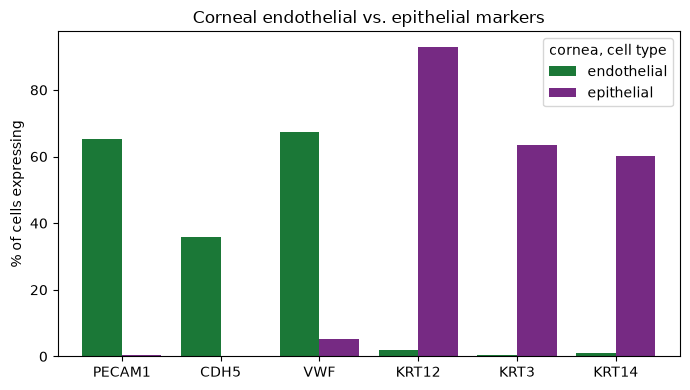

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
frac.plot.bar(ax=ax, color=["#1b7837", "#762a83"], width=0.8)
ax.set_ylabel("% of cells expressing")
ax.set_title("Corneal endothelial vs. epithelial markers")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="cornea, cell type")
fig.tight_layout()
plt.show()

The endothelial markers light up in the endothelial cells and the keratins in the
epithelial cells — exactly as they should. We confirmed a real biological signal
having read only the ~6,900 cells we cared about.

## What just happened

| | |
|---|---|
| Opened the atlas | instant — nothing loaded |
| Explored 815,769 cells of metadata | free — lives in the 31 MB repo |
| Read expression for 3,462 target cells | seconds — only their byte ranges |
| Loaded the 10 GB matrix | **never** |

The repository is a thin, self-contained index that points back at the original
file. Metadata questions are answered locally and instantly; expression reads
fetch only the bytes for the cells you select, in parallel. The same `select_cells`
call works for any selection — one donor, two cell types across several tissues, a
random sample — and only ever moves the data you actually use. Point the same repo
at the file's `https://` URL and these reads stream straight from the cloud.